# Payload thermal

A worked example of `quicksat`'s payload thermal model: the sample satellite's payload heat over the scenario sample's three orbits. It sizes the payload's radiator and its heaters.

**Run all the cells.** The notebook reads the files in `data/`, runs the scenario, and sums the heat that crosses the payload's boundary: the dissipation of its equipment, its heaters, the heat flows, and the heat its surfaces absorb and emit. Below are the account by payload mode, where the heaters are set, then by activity, over the run, by orbit, and for each surface. Then come the decisions behind this sizing, which the code cannot take: how the heater is set, the heater to install, the margins and the radiator's size.

For how each part works, such as the view factor to the Earth and the equilibrium ΔT, see `docs/power/payload_thermal_ref.ipynb`. For why the model is built as it is, see `docs/explanations/payload_thermal_model.md`.

In [1]:
# Change log. LAST_CHANGE and CHANGE_NOTE are typed in by hand. Update them whenever
# the inputs change, such as a surface, a heat flow, a heater power or a new
# scenario, so that the figures below can be read against what produced them. The
# run time is recorded automatically, and says how stale the outputs stored in this
# notebook are relative to that last change.
from datetime import datetime

LAST_CHANGE = "2026-10-25"
CHANGE_NOTE = (
    "The scenario sample's three orbits, with a 0.2 m2 white radiator at 273 K on the "
    "bus's +y face, floating, and the telescope's aperture at 273 K, fixed. The flows "
    "are 3 W out to the platform and the X-band's 5 W of radio output in downlink. "
    "The four payload electronics rows dissipate inside the MLI, and the heater row "
    "draws 22.1 W in idle and 0 W in imaging and downlink."
)

print(f"last change  {LAST_CHANGE}")
print(f"             {CHANGE_NOTE}")
print(f"last run     {datetime.now().astimezone():%Y-%m-%d %H:%M %Z}")

last change  2026-10-25
             The scenario sample's three orbits, with a 0.2 m2 white radiator at 273 K on the bus's +y face, floating, and the telescope's aperture at 273 K, fixed. The flows are 3 W out to the platform and the X-band's 5 W of radio output in downlink. The four payload electronics rows dissipate inside the MLI, and the heater row draws 22.1 W in idle and 0 W in imaging and downlink.
last run     2026-10-25 23:01 CET


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# quicksat is installed with pip. In a clone of the repository, use the package
# beside sample/ instead, so that it runs without installing. Either way the
# notebook runs in its own folder, and reads data/ beside it.
repo = Path.cwd().parents[1]
if (repo / "quicksat" / "__init__.py").exists():
    sys.path.insert(0, str(repo))

from quicksat import u
from quicksat.power.config import PowerSystem
from quicksat.power.consumption import PowerConsumption
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.thermal.account import run_thermal
from quicksat.thermal.config import PayloadThermal
from quicksat.thermal.plots import heat_plot
from quicksat.utils.plot_helpers import STYLE

plt.style.use(STYLE)

## The inputs

The account reads four files from the power sample's own folder, as the power budget does:

- `payload_thermal.yaml`, the payload's surfaces, its heat flows and the Earth's two constants;
- `payload_consumption.csv`, with its `thermal` column, which says where each row's heat goes;
- `power_system.yaml`, whose self-shadowing switch shades the surfaces as it shades the panels;
- `scenario.yaml`, the run, with its 3D model.

The radiator is a white panel of 0.2 m² on the bus's +y face, which faces away from the orbit normal in nadir pointing. The sample's 13:30 LTAN puts the sun on the orbit normal's side, at a beta angle of +25°. So the radiator sees no sun in nadir pointing and yaw steering, and only edge on in sun pointing. The Svalbard pass rolls the body, and gives it a little. The aperture is the telescope's opening, flush with the nadir face, with a black, vaned tube behind it. Its 273 K is the mean of what shows through it, mostly the vanes, which see space and run cold. The telescope's control holds it there, so it is fixed. The four electronics rows of the payload dissipate inside its MLI, and `payload_heaters` is the heater row.

In [3]:
DATA = Path("data")
thermal = PayloadThermal.from_yaml_file(DATA / "payload_thermal.yaml")
payload = PowerConsumption.from_csv(DATA / "payload_consumption.csv")
power_system = PowerSystem.from_yaml_file(DATA / "power_system.yaml")
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
account = run_thermal(thermal, payload, power_system, run)

for note in account.notes:
    print(note)

## By payload mode

The heaters are set for each payload mode, so this table is where their powers are set. Every term is a mean power over the mode's time in the run, positive into the payload. The net is the heat that builds up when positive, or the heat lost when negative. The ΔT is how far the radiator would move from its 273 K if the mode went on forever, with the aperture fixed.

The balancing heater power brings the mode's net energy over the run to zero. It is never below zero, since a heater cannot cool. The account takes each row's power without its margin.

In [4]:
# one decimal for every figure of the account's tables
def styled(table):
    numbers = table.select_dtypes("number").columns
    return table.style.hide(axis="index").format(
        {
            column: "{:.1f}"
            for column in numbers
            if column not in ("occurrences", "orbit")
        }
    )


styled(account.mode_table)

payload mode,time [min],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note,balancing heater [W]
idle,227.1,15.0,22.1,-3.0,0.9,6.7,21.8,-79.0,-15.5,-58.5,-22.3,,37.6
imaging,25.6,115.0,0.0,-3.0,0.0,18.3,25.4,-79.0,76.8,32.8,68.0,,0.0
downlink,31.8,85.0,0.0,-8.0,28.2,2.7,19.8,-79.0,48.7,25.8,47.9,,0.0


The heater row's power in each mode, against the power that would balance the mode:

In [5]:
heater = next(load for load in payload.loads if load.thermal == "heater")
for row in account.mode_table.to_dict("records"):
    mode = row["payload mode"]
    print(
        f"{mode:9s} the heater row gives {heater.watts(mode, margin=False):5.1f} W, "
        f"and {row['balancing heater [W]']:5.1f} W would balance the mode"
    )

idle      the heater row gives  22.1 W, and  37.6 W would balance the mode
imaging   the heater row gives   0.0 W, and   0.0 W would balance the mode
downlink  the heater row gives   0.0 W, and   0.0 W would balance the mode


The heater row gives idle less than its balancing power, since idle also takes back the heat of imaging and downlink. Those two run hot with no heater: their dissipation alone exceeds what the radiator gives out. The section on the heater, below, works out the row's power.

## By activity

Two activities in one payload mode can differ. `nadir before eclipse` and `eclipse in nadir` are both in `idle`, but only the first is sunlit. Its aperture sees the sun, low over the horizon, and its surfaces the albedo. Each activity counts the slew into it.

In [6]:
styled(account.activity_table)

activity,occurrences,time [min],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note
power generation,4,127.0,15.0,22.1,-3.0,0.0,12.0,17.6,-79.0,-15.3,-32.3,-22.0,
imaging 45 deg lat,3,19.8,115.0,0.0,-3.0,0.0,20.4,26.3,-79.0,79.7,26.3,69.9,
downlink Svalbard,3,31.8,90.5,0.0,-7.1,20.4,4.8,19.5,-79.0,49.1,26.0,48.2,
nadir before eclipse,3,13.7,44.8,12.7,-5.1,32.7,0.0,25.9,-79.0,31.9,7.3,33.8,
eclipse in nadir,3,92.2,15.0,22.1,-3.0,0.1,0.0,27.1,-79.0,-17.7,-27.2,-26.1,


## The net heat over the run

The net heat into the payload since the start of the run, over the payload's modes. Where the line rises, heat builds up. Where it falls, the payload cools. The model has no heat capacity, so this is an energy, not a temperature.

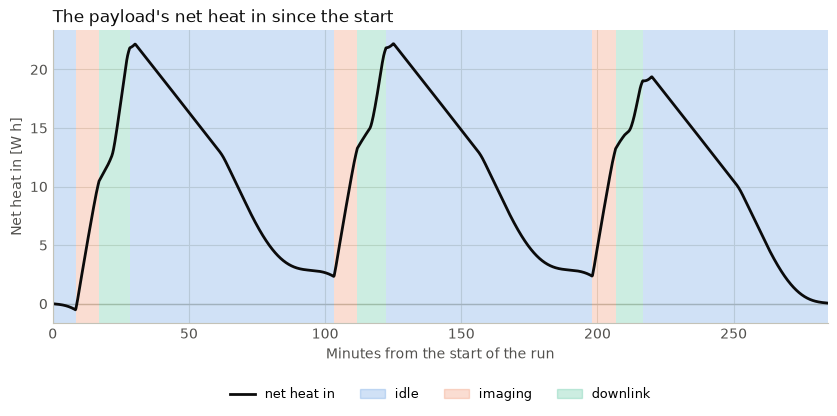

In [7]:
heat_plot(account)
plt.show()

## By whole orbit

One row for each whole orbit, counted from the start of the run, as the power budget counts them.

In [8]:
styled(account.orbit_table)

orbit,start [UTC],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note
1,2026-10-01T09:00:00.000,32.4,17.5,-3.6,4.9,7.3,22.3,-79.0,1.8,2.8,2.3,
2,2026-10-01T10:34:51.055,31.8,17.7,-3.6,3.9,7.3,21.9,-79.0,0.0,0.0,0.0,
3,2026-10-01T12:09:42.109,31.3,17.8,-3.5,2.8,7.3,21.5,-79.0,-1.8,-2.8,-2.3,


## The surfaces

Each surface's properties, the range of the sun's angle to its normal outside the umbra, the time it sees the sun, and its mean heat over the run. A radiator should see as little sun as it can. This one sees it only in the Svalbard pass, and the sun lying edge on in sun pointing counts as none.

In [9]:
styled(account.surface_table)

surface,part,area [m2],absorptance,emissivity,temperature [K],fixed,lowest sun angle [deg],highest sun angle [deg],in sun [min],peak sun [W],mean sun [W],mean view factor,mean albedo [W],mean Earth infrared [W],emitted [W]
radiator,Radiator,0.2,0.2,0.8,273.0,False,75.6,140.3,3.5,5.5,0.0,0.2,0.7,8.9,-53.5
aperture,Aperture,0.1,0.9,0.9,273.0,True,25.4,180.0,26.5,83.4,3.8,0.7,6.6,13.0,-25.4


## The heater: a decision

Sizing takes decisions that the code cannot take, and the first is how to set the heaters. Each mode's balancing power, in the table by mode, would keep every cold mode in balance on its own. This sample takes another way. It lets imaging and downlink heat the payload up a little, and gives idle the heater that takes that heat back. So the heater runs in idle only, and its power brings the run's net energy to zero. The heater row's 22.1 W in idle is that power, as a thermostat's mean. Its 0 W in imaging and downlink says that the thermostat stays off there.

In [10]:
# each mode's net energy before its heaters, and the idle heater that brings the
# run's total to zero
modes = account.mode_table.set_index("payload mode")
hours = modes["time [min]"] / 60
before = modes["net [Wh]"] - modes["heaters [W]"] * hours
for mode, energy in before.items():
    print(f"{mode:9s} net before its heaters   {energy:6.1f} W h")
print(f"the run's net before its heaters  {before.sum():6.1f} W h")
print(f"the idle heater for the run       {-before.sum() / hours['idle']:6.1f} W")
print(f"the heater row in idle            {modes.loc['idle', 'heaters [W]']:6.1f} W")

idle      net before its heaters   -142.2 W h
imaging   net before its heaters     32.8 W h
downlink  net before its heaters     25.8 W h
the run's net before its heaters   -83.6 W h
the idle heater for the run         22.1 W
the heater row in idle              22.1 W


The run balances, but each orbit does not quite, as the table by orbit shows. The sun that enters the aperture in the Svalbard passes falls from one orbit to the next. A thermostat follows such changes, which a fixed heater power cannot.

The heat that imaging and downlink build up is lost again in idle, so the payload's temperature swings. The model has no heat capacity, so the swing is an estimate outside it. With the 45 kJ/K of the explanation's example:

In [11]:
# the net heat's swing over the run, over an assumed heat capacity
CAPACITY = 45  # kJ/K, an example, not a property of the sample
energy = np.asarray(account.running_energy.to(u.W * u.h).value)
swing = energy.max() - energy.min()
print(f"the net heat's swing over the run  {swing:5.1f} W h")
print(f"over {CAPACITY} kJ/K                      {swing * 3.6 / CAPACITY:5.2f} K")

the net heat's swing over the run   22.7 W h
over 45 kJ/K                       1.82 K


A swing of under 2 K an orbit is small for a first pass. A payload that must hold its temperature more tightly would take a larger radiator and more heater power, as the section on the radiator's size shows.

## The heater to install

The heater to install must cover the coldest mode for as long as it lasts. Here that is idle. Its balancing power holds the payload through a long idle, such as several orbits with no imaging or downlink. The heater row's margin of 20% then adds to it:

In [12]:
# idle's balancing heater, with the heater row's margin, and the run's coldest
# moment before the heaters
balancing = modes.loc["idle", "balancing heater [W]"]
net = np.asarray(account.net.to(u.W).value)
before_heaters = net - np.asarray(account.terms["heaters"].to(u.W).value)
print(f"idle's balancing heater             {balancing:5.1f} W")
print(
    f"with the row's {heater.eqpt_margin:.0f}% margin             "
    f"{balancing * (1 + heater.eqpt_margin / 100):5.1f} W"
)
print(f"the coldest moment, before heaters  {-before_heaters.min():5.1f} W")

idle's balancing heater              37.6 W
with the row's 20% margin              45.1 W
the coldest moment, before heaters   51.3 W


This covers nominal operations only, the modes of this scenario. It leaves out a safe mode, which may hold another attitude with less equipment on, and needs a scenario of its own. It also leaves out the redundant heater lines, the lowest bus voltage, at which a heater gives the least power, and any margin beyond the row's. The run's coldest moment needs more than idle's mean, but it lasts minutes, and the payload's heat capacity covers it.

## The margins

The account takes each row's power without its margin. That is the safe side for the heater, since the payload is then colder. For the radiator, it is the optimistic side: with the margins, it has more heat to give out. So check the run with the margins too. The payload should still balance, with the heater lower:

In [13]:
# the dissipation with each row's margin and the system margin, and the idle
# heater that then brings the run's net energy to zero
assert power_system.system_margin is not None
system = 1 + float(power_system.system_margin.to(u.one).value)
inside = [load for load in payload.loads if load.thermal == "inside_mli"]
extra = 0.0
for mode in modes.index:
    without = account.mode_watts[mode]["dissipation"]
    with_margins = system * sum(load.watts(mode) for load in inside)
    print(
        f"{mode:9s} dissipation {without:6.1f} W, with the margins {with_margins:6.1f} W"
    )
    extra += (with_margins - without) * hours[mode]
print(
    f"the idle heater for the run, with the margins  {-(before.sum() + extra) / hours['idle']:5.1f} W"
)

idle      dissipation   15.0 W, with the margins   17.3 W
imaging   dissipation  115.0 W, with the margins  137.6 W
downlink  dissipation   85.0 W, with the margins   98.2 W
the idle heater for the run, with the margins   15.4 W


With both margins, the idle heater that balances the run is lower, but stays above zero. So the radiator still copes, and the thermostat only runs less. Had the heater fallen to zero, the payload would warm from orbit to orbit, and the radiator would be too small.

## The radiator's size

The radiator's size is a decision too. A larger radiator brings imaging and downlink closer to balance, but idle then needs more heater. Here the radiator is typed in on +y at other areas, with every other input the same. A typed-in surface is not shaded, but this one sees almost no sun anyway. The two last columns are each mode's net before the heaters:

In [14]:
# the radiator typed in on +y at other areas, with every other input the same
text = (DATA / "payload_thermal.yaml").read_text()
rows = []
for area in (0.15, 0.20, 0.25, 0.30):
    sized = PayloadThermal.from_yaml_text(
        text.replace("{part: Radiator,", f"{{normal: +y, area: {area} m2,")
    )
    table = run_thermal(sized, payload, power_system, run).mode_table
    table = table.set_index("payload mode")
    net = table["net [Wh]"] - table["heaters [W]"] * hours
    rows.append(
        {
            "radiator [m2]": area,
            "idle, balancing [W]": table.loc["idle", "balancing heater [W]"],
            "idle, for the run [W]": max(0.0, -net.sum() / hours["idle"]),
            "imaging before heaters [W]": net["imaging"] / hours["imaging"],
            "downlink before heaters [W]": net["downlink"] / hours["downlink"],
        }
    )
sizes = pd.DataFrame(rows)
sizes.style.hide(axis="index").format(
    {column: "{:.2f}" if column == "radiator [m2]" else "{:.1f}" for column in sizes}
)

radiator [m2],"idle, balancing [W]","idle, for the run [W]",imaging before heaters [W],downlink before heaters [W]
0.15,26.5,8.3,87.0,60.1
0.20,37.6,22.0,76.8,49.2
0.25,48.6,35.7,66.5,38.3
0.30,59.6,49.5,56.3,27.4


This sample takes 0.2 m², and lets imaging and downlink heat up a little, for a modest heater in idle. Another systems engineering or safety decision could design the payload colder, with a slightly larger radiator. Imaging and downlink would then come closer to balance, and idle would need more heater power. Both are valid designs, and the code cannot choose between them.

## Changing the sizing

Edit the files in `data/` and run the notebook again from the top. The notebook never writes them.

For example, set the heater row in `payload_consumption.csv` to each mode's balancing power, the other way to set the heaters. Each mode's net then comes to zero or more. The power budget reads the same heater powers, so run it again too.

Or put the radiator on the other side, the orbit normal's, by typing it in with `normal: -y, area: 0.2 m2` in place of its part. The sun then lies on its side all through nadir pointing, and the radiator absorbs it there. The table of surfaces shows how much.

Or give the radiator a different temperature. A colder radiator gives out less, so the payload needs less heater power, and runs hotter in imaging.